# CLIP–Jev：锁定方案 → 独立评价 → base 蒸馏对照 → 汇报

2026-10-13｜中文分步版｜Google Colab / Tesla T4｜不微调 CLIP

本 notebook 直接读取 **1013实验成果包与结论.zip**，复用18个已选模型，新增 **base 原始软KD的3个种子**。不重新搜索α，不重新运行Teacher。运行代码已内嵌，不需要另外上传 `.py` 文件。

**重要：这是一份后续实验工具，不含伪造的新成绩。** 3次正式GPU训练、新图片特征提取及最终评价，需要在你的Colab/数据环境运行。已有成果包中的训练成果不会被覆盖。

四部分：
1. 锁定数据、模型、训练与评价方案；
2. 准备新图片留出评价和旧测试历史对照；
3. 训练base KD、锁定全部21个checkpoint，然后统一评价；
4. 导出表格、配对区间、图、案例记录和汇报包。

第二部分只准备评价输入；真正评分放在第三部分全部选模完成以后。请按顺序运行。

## 先明确研究目标

“冻结CLIP＋MLP＋常规KL蒸馏”本身创新性有限；微调CLIP本身也不是创新。当前合理定位是 **冻结视觉语言表示上的决策知识迁移实证研究**。

本轮回答：Jev软目标是否优于真标签/硬标签监督？是否优于未加载Jev适配器的base教师？校准的概率收益能否迁移？图像是否有额外贡献？

如果要发展方法创新，我更建议下一阶段研究 **有证据约束的成对变化蒸馏**：当图像中的可见事实变化时，学生是否学到教师判断的对应变化。它是待验证方向，不是本轮已经提出并验证的新算法；随机换图不产生可靠的新标签。

已有相关工作：[CLIP-TD](https://arxiv.org/html/2201.05729)、[CLIP-Adapter](https://arxiv.org/abs/2110.04544)、[冻结局部表示与组合性](https://arxiv.org/abs/2604.11496)、[Visual Jev](https://arxiv.org/abs/2609.25845)。不能把“加小头”“置信加权”“使用Jev”单独写成首次创新。

## 运行前准备

- 把原始ZIP放进Google Drive（下方默认 `MyDrive/1013实验成果包与结论.zip`）。也可以直接指定已解压的成果包目录。
- 准备原来的完整Flickr30k图片目录，包含未用的200张dev图片；成果包仅带24张案例图片，**不够进行最终评价**。
- Colab选择 **T4 GPU**。新训练沿用历史 torch/numpy/CUDA；安装后若要求重启，就重启并重新运行检查单元。
- 新输出目录必须与旧成果包目录分开。重连时保持同一输出目录、配置、代码与环境，已完成训练会跳过，未完成训练从最近5轮恢复。
- 若完整运行前已查看过剩余200张图片的模型成绩或曾用于决策，不要称为未见留出；在使用史中明确记录，并另设计评价。图片ID与像素去重不能自动证明包外未用。

# 第一部分｜锁定本轮方案

主方案：Jev原始软KD，α=0.75，τ=2。概率对照：Jev校准软KD。保留CE、硬KD、仅图像/仅文本CE及全部三个种子。base KD采用相同α，不声称这是base自己的最优超参数。

每个新学生：30轮、batch=128、AdamW lr=0.001、weight decay=0.0001；按原val_select Macro-F1、NLL、较早epoch依次选模。冻结CLIP。只新增3次学生训练。

### 1.1 检查并安装匹配环境

如安装了依赖，本单元会提示重启内核，这是正常的。不要在安装后继续使用旧内核中的torch/numpy。安装可能需要几分钟。

In [1]:
import sys,subprocess,importlib.metadata as metadata
from pathlib import Path
assert Path('/content').is_dir(), '本运行入口面向Colab；本地请使用独立环境并配置等价路径。'
gpu=subprocess.check_output(['nvidia-smi','--query-gpu=name','--format=csv,noheader'],text=True)
assert 'T4' in gpu, f'请选择T4 GPU，当前：{gpu}'
def version(name):
    try: return metadata.version(name)
    except metadata.PackageNotFoundError: return None
commands=[]
if version('torch')!='2.11.0+cu130':
    commands.append([sys.executable,'-m','pip','install','torch==2.11.0','--index-url','https://download.pytorch.org/whl/cu130'])
pins={'numpy':'2.2.6','transformers':'4.57.1','huggingface_hub':'0.36.0'}
need=[f'{k}=={v}' for k,v in pins.items() if version(k)!=v]
if need: commands.append([sys.executable,'-m','pip','install',*need])
missing=[k for k in ['pandas','matplotlib','Pillow'] if version(k) is None]
if missing: commands.append([sys.executable,'-m','pip','install',*missing])
for cmd in commands: subprocess.run(cmd,check=True)
if commands: raise RuntimeError('依赖安装完成。请在“运行时”菜单重启会话，再重新运行本单元及后续单元。')
import torch,numpy as np
assert str(torch.__version__)=='2.11.0+cu130' and np.__version__=='2.2.6' and torch.version.cuda=='13.0'
print('T4/FP32训练环境已匹配。')

T4/FP32训练环境已匹配。


### 1.2 挂载云盘、设置三条路径与使用史

通常只需要修改 `SOURCE`、`IMAGES`、`WORK`。不要把`WORK`设置成原成果包目录。

`EXPOSURE_NOTE`按真实情况填写：是否在其他聊天、脚本或实验中用过剩余dev图片来调参或看成绩。不确定可以保留“不确定”，报告会保留这个限制，不会自动称为严格未见测试。

In [3]:
from google.colab import drive
drive.mount('/content/drive')
SOURCE=Path('/content/drive/MyDrive/1013实验成果包与结论')
IMAGES=Path('/content/drive/MyDrive/flickr30k-images')
WORK=Path('/content/drive/MyDrive/CLIP_Jev_final_round_20261013_v1')
EXPOSURE_NOTE='仅确认与当前成果包所有已用图片隔离；剩余dev图片的包外使用史尚待核实，不能保证完全未用于其他决策。'
BOOTSTRAP_REPEATS=2000
assert SOURCE.exists(), f'请修改SOURCE或上传原始成果包：{SOURCE}'
assert IMAGES.is_dir(), f'请修改IMAGES，需完整图片库，不是包内24条案例：{IMAGES}'
print('新输出：',WORK)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
新输出： /content/drive/MyDrive/CLIP_Jev_final_round_20261013_v1


### 1.3 恢复内嵌代码、核验输入与锁定协议

本单元核验6000条base输出、ENC顺序、样本与特征对齐、输入文件SHA256、18个复用模型、划分隔离，并写入不可静默修改的协议。成果包为只读输入。

In [4]:
import base64,gzip,hashlib,importlib.util,json
EMBEDDED_SHA256='3a85500a36da369d650a15a317339714a8663b976b98188b110a52893382ea58'
EMBEDDED_RUNTIME='H4sIAAAAAAAC/619aZPcVJbod/8KjQmeJFuVVVnljSpEBO2l8WtwE0D3xJucjAxlprJKXbkISVnOsnGEWbyv0MYsNhiDAQ/YZUPTeDcR8wPe+w/TpayqT/yFd5Z7pStlZtn0TEfjUl7d9dyz33OPNm7cuCfoHHDb2s6X976qNby20xwLOt12XdvfCeYbzc7+gvZ6pxvUXM13avPOrKt5oRa4Tn2s024uzmhtdz9VxWIv7DSdyK0XNm7cuKERdFrQJpprelXNa/mdINJehZ/8og71Iq/lyjfyt6Xhvwc6bfFUd5uRs0FUqnWaTbcWeZ12aGm1cMHS5pwQ+4eHqNW0NK9jaX8JO21L60CNwGnXOy1LC+e6kdfk/iyt2/XqlnbA8xte05U9t7stf1FzQq3tb9jw+u7du17XbK00OTG5rThRnLA08VRMnibLG17Z/cZLf+SK+s7duqXpf9hVmXOCungMnP3iqebAHAOEDBbs3F3xWgBI8Ry5vUjUqzqhq5c34FZUXtv9Z+hZn6pv3+LUGs85kztq27Zv31KsTja2NCZdZ/u2qa2NCcdpbGvAjHboG3a9+MaLstXWLe7Edndq+0SjUS0+VytWt7putVGcmti61d1R3eY0pqaee67o1PUNr7649zVagpFMGRdjWppSINdFpbjUZN6mtUGT/zPyS5UdDHRG6zTLGzbU3Qbg0ptdL3CNzryltcJZc5p69BpauxNp1U6nCW/MadhML3S1PzvNrrs7CDqBgXW5h3DOMXzRbs4WKFGA0smt2wyTivd70RxhH1QsdHy3behBVTdxxxvTyRIanUADXG1rXuQGRtNpVevOdKOA2G4UJya3bMJ/TKuq6zChuULXR6w1qjxE4EbdoA3Fc26v7s26YWSYcoVO/S84Q1kHUbTQ7Dj10JBzwjoEUsNt1zp1rz1r692oMbZjLPRmddPkjjr7Q7WfktJRaNL0Q5z+U3ZaCP2mFzW9thsaJkI8LIRR4PkGbA3BNXJa8CMZTtJood3Zb0gyNRIqNeaAT4T2DtM0sZ8GvjD0Z//Ps61n65VnX3r2lWdf183NekXfjCRYwH+2GCaCqzS9TSCDE3VaXs3wLRzMEXvq22JBM5pf8J3AbUeF1nzdCwz+EdpvBF3XcnteGFU68/SL9yRq+bZfwM2vtB2YjV/AP5v1wuAcoBB6izynqSsoAx0IdOkl6KI1CvsDwBCDpjgDPxvNbjhnwGMnLDTCxXbNgDLgLu2OYSYTgd3wm04NJiHR1llwcaULAOFk3bSjdeBGobFgue2wG7gVJ6x5nr3HaYau5bXrsGJ70nKawJthVW1+YRZoiwHgtMESY7C75sAghq4X/tLx2oYyWm/YaPlBNuv/3tYJz3qIZwvmkGFp3Ebgugd4dUixKVFL1KTNChm5mP4lldg2NbG0hr524e146dP46JF46V7/wr343Me/Pvz0oH/oH4ffWf7ls5UPP4nPXlm5tBQ/+vDXh6fjc9/ED+73L59YvfVT/+OzK5++1794O176fO2701BfbKoLq5iWkOepqcTLnISXAPKFt1kuIsyyJi6TxEFvQtvrFF4HEmrP7v2jAZIRacsGbjGj7behv8Iurxb9a0DcJbQantusIz6GdhOAYXCHpYmyifUZx+YAKFA5LSAWIKZDYyabGhZm3YjeGLldkSyEltVtoxw3QpLpQGbAp8S6QGj//nd/0JrurFNb1P4N1AGanKX96Y09Yzu0RtOZnXXrsjAKAIhB6DQ1P+hELJVBANddEKgRoKgGbCdwqJjUAYIPD4pjMklzgWnRD5qKhDC/KXhhBekc0KQGwtxDDhTaJX5Z3kxgEzWD2WanaujFif7l48Wp/kdfV5YfPIhPXl2+f235wce6qex/wu9xxKfkJCQeGKmx1bj+4ms7X9r7590FJCHdqsPGiplUWPDYiEtifWbaB3EVoXwU/s3z98BfuRktN3KQp1RSbj1bnWe2cyCdNeMrEw3wGOMAMTWChQnUg0WhG2WLQQTruKPx+e/Xjp2Jr51ZvXMrfvyebmZ6RcJ2kbAPFLx2o8NtswOL7cnsTKcdee2uO1DPtxlWLjNDmA2KJNARgfrMgdpyST52HbigSHoLbiXqUB9pO7kSXsDqzydXPjytm8Pm6KdMZuB1dkAQdLBQ+FMJvQOubfOE6Yelx3d+XP32q/jsqf7FY8sPfo6vfRvfPrd898zKjW+QsEeunneapYcrRUdCrUKrUDBDQXACPC/7qbC65US1OSQMn7bQxy1Mu0NYGP64Hrjd0K1XForjYdRFKRKOh67QpxmNU7Zc3pDHMjEGIBgowXr/8nfxhVvLdw/3TzyOj9/uHz/f//xyfPrI8t2bwHi1EfPVmFnrGZ4rOga+J8RipxG1nJ5xQGzbAbvtF5zQCQJn0Thg1aNF38UisE2caNsW2AL66fZ848DYgQI2HSta867r170WEzQyVDGaC9gYdluDVXhwIMHAq4XGoiUVykV1+EUxvNeOUBlRX/niFU3L3JBDsDkHXtkEyEXTmgJ0AAurjagOJhcJGbMAwtbgF4b/gj0hChDY37yzcvZY/OjLlZM/j/c/vB0ffhg/fCe+e1fPjoOzaTZrzU5IY8Iqi6ZVtADnmnbRHdua9oXb9+gD2L749EXRSa2FqzkAAiY0jCmYYmap2HW9XgAyqbUshE7BCWYR1EUgyCL30LAnN9VahbrnzHbAjDTMcWgFdbwWzARe4IQmzM3iqZi0c2uuPVEgSmqA/GjDT2oHVbAwCABFbUMZ0bYXuWXVa4c46xbAEAcx0i5AVQcAhrgEA5dgPScmKVV8MA5nXdDqFebg9Wzq0a5uUNiI1ys47UVkdDDRzTb8bLlO2zA3OdXQENMreb2yKB5L56CUZjCehEXLqQWdSqPICAMKo6hoaU6t1gXJuSjeiCGS9wOMplGs7Ja9oPZgQcG+pKDIBTuTgsnykD7azaaoMAbwbHZmEZlqTbAF/BLuPUOL0de0FssW4FNxEnbQHD0vAFdxQvTqopTXqoHnBqLEMHwcyl10jSmztFg2N22aNAVmjO4TgdsNgWHZgEaRkFBS53SdCBVY4Cag4PSsRcurhxaZ2hV8ajltr5GqO5JqehnqTCpZkxNbdjA59gpMCgnXmZocoN+eJFedHCkrJ+7Fj98eSqUwlWTmtl0KSnoIZlYT56iXCT8DxE85kTIQLfem7d2lrV29H99PpE+m38Vcr02n6jbX77H/xbGVm4+H9paATRIRWHSmOgL8NmAUWU8vm+uNFF96HL97DleQGW3Bimyw/qzprcXJsoVP8DCNVnZ5JGdD/EQ31SyYoUELrCTgMKGd4XRbEv46qlU0tJUl4TLIHofNBOeLc50ubp3aVraQHyyMAebIDrcNToOaQO3psrWwKVJqyqHj40f7S39fu/DJ6q1bukBsNPArArtDmMEBK4GwhRJL2sktm20oKgKJF9hkLSQonVkIqqfQFWxlq6TDg1BbAWFwzvg2aUdV5K+knpzxeP/ukfjMh/Ffj8d3Tw/FJWgduAsekq1etm3p3hKkIl9lMYO0J2JFoCXhktkU9b3afNMV1ijqVI6izdsH56ed0ny5UOv4wLAJH+cRH0t6T7f0RfgPEBr/lcitlw+xVMiwjjrWL1vwZ5H/UE16SBtaQQAwhjKEMSwrCDIsnnfOay+AntUJQD2Yl54teBL+DCgSUm82FFsHZU+lqJV00U4vo2oTdpuRXSonEg4wYK5Tx6ULJ2VpeqxYzjq6QtelGuTtzGrIXkP0YNvo7htUn2t2G71KNeqoRuomTweb1gBZqDVuNrYnjIJSHBHL8K85xFoYsXh9HNrSzvgdEOW4Yvav2ZnyBDEzPYMB1FDAUcr4IRVnZXlwkY3MhJymP+eMB902zKehH+QuD3HxRGH71spBXNYhfQiseGsb43q903bFBqL2CCVVVPL9SP9tS1Jt2Pxs8xMU05r5n5+HyknQbcMt0W/Tv341/vxU/8yV+LNz7LHJWWiMsQXHB+OobrA+xAjHfyycNOGJlc7CRpHjq5bgwAzFHLLqFg/GBOkHLlr6SGcWHVtYGhgOHXJ8tTuRa6HHOYKBHB9sUB/YQmhPTkxMpLRrYauUgNPpsBMD3+at3ER2dCIaM2/gYj8sKaAC/Mi/pz4tffXxX+MjX5ORdbZ/8Tb+PHafLar4lyNrVx+sXLq7fP+DlVM3Vr4/lWPBqNpkFio9veYLdnEC+r51Z3XpNvQEHaNf7dj9tUtHYaj42sXlR7+sXLgen/vx14eXkEVfXUKf3O0f0McGz0c/SQpzYw5A8gUCpaX3b34VPzy3euu95Qd3Vo/9Lb79voYvtP6Nq2tHzsS37q0dO7N27Fj/izuix06znmMOiKhO5NgHD80AWftd2KaDh9TR63ZJlyJzHBXZipQzwmOjJ7wVpgg6XHu20uzU5uXbOTw7ajTGGXmgC8Eq0g5yFJi0ABRDhMZDKu56HI87qFFT6Xiw2l/cBVnr6fsGes9PWUrqcJzFldOte9HA+GmtRLKj3sCdpZIkZK5Jg0HrBadZaXiReGKpBD8iaA4sNAG+pOzGkOEOhofEZFKLLLTaNI4hB9qGNGcZmVG2QJHCppOxQBLhWKVGuuE4BigNupUtU1eYMiREpFJYtrNqFuDc+LAeuXy9ZVmDTZWBzQ3DfHhiDqRxACttA5F8cad/+QZY+xm1SJzBVvCQy80oDeyd6n9xde2706yRqeMhkNEBR5avAJxi+BIFlbBCmfyWuALy1w1MNlPVzk6npAhvfTNVgQ1IfEM8Q2Be7AziSfLqUEhgfSknOoE3i9q6WCBOZ116NbP4itCczk95yGbCCuRICbcQa9HLsB2WHp+9srp0c+XBu2sX3mZ1d7i1xEM8FXFnBo1cB4RYUKFKimr9v90FjRl8/7Ov+/fPP9WoI3lVZkjlrTIgIE587KhwcZ77WDF8um11F56CE2UnCcVo4S4AWnSCuhvgZEo6niHvw3NkYW9QrQETw7bzS0zpjQaVILX0NxiQGpu0bCb3j19UkUxMDLSKto0OcvOfY3IpSQj76skcAbQssBnsg+vZzEFwaChngIbCqQ8GR6IlYLH2v2gtoBn0P/o2Pv4BmI7xzY/jy9fj86fB3mY/P46NteRhNXbHvjMQSun8n056QV/VRQ/srKzTYjpIl4G1Dw2oHtgKVoFcnc1LAL8ow0fifgL8ZWFuwbKwLy3dWOSHsJNrj86LnQREnm2jpMeuco4Uxe+R653ttVTCVS2qdQC0IdGhNbSFOSB6jCrgbKfuEk3TbNnUQUdQFexQ2w7gX9UMZZ9MaoCiPF70OxEwHA8NUzqQH1y7OAG9/B3qRsnyM45x8vh0Zj0wl5SliwWVR/umDyTeL9ycYZ7pA4lni+bEg2gZ1xZgUIUAEdpZi5dlVtCJOrVO0yY9f95r122dNDLgiRWKOKpQxBGqdaT4hzbZpBbbAqEtbFiLbC0bbC0rcrr2ZMFy/U5tLrSnJlKFqYqnCXyMU5zcYTUDuzAxUbT2u97sXFSpuzVnEUugKDGpbYXMtVfQLTu2pzijRR4udj+Af9/LL/NP1wmaHtC2RgMraloLMMVOTEtYcNWperCVixU8Hgpg7fnYmLa7vyIFmS1jYjQMqbK0aC5wXbLPKYhpv6YAXhnUxcNe4uMMWeyyDiAl5CKzhc0oEbG0xcoYAHbW7slonHNeCFvowXwryPRs3WmiCFjUFjx3v1ufUSqA4d8Ci8oD/kCz161BA2qgJDua73hBaJfIs+ib6QkWhSaVrZpn61gFvRW4stRC0zpo2jttzXeDMXJn8PGNRuEoM1rD60EZQdmtMzxnsG4NMNRrutpzW5+d0bptkG3dEDYFLcFmB/YHsBfGj9wAAByqIU4kjaSpyaKJz4pRGxEEkNKCBUINY2DUA+FKhU4WK8JCJWvwiQfQMxpqOrY4fsY247okKqH8y59CxGF8A9dD1KlETjDrRoohIA6s28SRrey59ZN1GUUilFPgEG8Ls7LdqjWdMAQi6OLSgKtUvTb9AL6THOdYLa8NQmI2mrOnUhdz2jHrRtR9xZkFILQwAkacIhxQj4VyfBt16eQogTYU1hIxxeis1kkP+OHVYz+tnD3268PTa5993v/7qdVbH4I6BGYtFOpDTm/QiYfOALRM4T92CpA/gcxS/Mci0B+wDySbY8uHpETCHPfXSpRe+SDjhIgzVbpt0q2Bwg2nDTTrcMSFH3idwNIIqkTzWobohdQi6LUc3z6oA/Acr4kw1KfBGG+7XQBYU58uWjoxK0fstj49Ccb1LLBmP7SVyMsCzMkBPZPggP8IJ2YTHkNWrFjdyepYrOSgvpHOXj17a2gBBrAY+ixSEAtKk3QdaCenPyTYoAH6iNCr9sAU5oOpiT9U9u7CrQ/cVmcBdOIGMAJDL/zFnyVtKG2AbIWqAkdb9G3UIAAseHQ3qZelh0SdIrSl8MB6OGQmdFhSrxtQCTqcdxdtAyZnQc+ZPuCFdJgSyIb0tMAMPVFnbOgyOciyG8kP5CV2Qz8IJYdoeVaqTdjwOHB+RnC0JTRRZ1CgXS4nnADVEFsHVAOBzM9SuMxB/U43UsxYJAHGkhLMo0ybmF8z1CG9Av4mB1P/Yi8kz1l3ZgIaAifACx3tblNTRinBCOUhwRciNgvHQ73eqz9PQ6rK6kA39gKTt9OetznmU9uEoYDhdC6UVH9LhM0B7PA8zKJaaQycaWZiP4X7edarwi7hcEQHuHuziAA8jQKoWC0RfjlLMMKKAu2JtgdDMWSn5gs2kT0a2Ze/QyfdpccrJ47F577rXz6hHcxUPQQa2xcYJXf7/eX7Z9e+fC9e+lQ7SM0PsWNv9d1Ha599svbg49WrX6OyDcbThXuJFyIxnpANoG+2E8CfpH8L0V0ADxYwjcA0yH+rq1hjwTvTLE3TuGWVq5ZACBgqGnGMG8gBpedA6Ter7pumBC7CTc6ynHH6VlKFyahFPUtLGZG9r9N20zC4P4IikxyxhRqo4G5B29fRSK4repeGAr6J+r42WdRSb3SowXBagwLrk+A3kg5ILDB2ScdfKB/xGQrpUANVLZba6RAVFsf6jBqsNiQ+DdAnXQ7G4uOKFPbKYe7doIn4jMgEvSVvFUBwcFvYbnqVBRcpXgj6PIWlTUZEWcFQwJrmosgPp8fH57qzINJmG07NLdQ64ygfQTyE4y9x+R4of2XL+Ov7Xt479ufd48J9Pn5QxrQfGl9nRslxYXZ1BfhJwVfw10I9DBDQLu6YoGNDGMEHWeYmEVmKSJXvMhFa6mGHIsDsYb6RdV2rJuAtc9nE0USMtkyUovX/dn3t2El2WMTnj8dnr8SX7gOtrpw4DoQovYDIF/47PgzuQfoE1nVLPKWHQ0AJZ7WOtkLDijUIVMsJFnVzszF8qUeJo+AB9IGlJ+cV7OnhKOFMsK8MgQ7EwNJ2EePnbJ3c+PLtkGkgJsjX6McQbtNhrqq0XxNdikfjcz+OnK7AR9mz9TSdcqB/dTFChilQQo1VTUxd9YiD9dicIkr8KFcIqJluoWrMKHSQahq4nzlHns0nhJYC6mE1EmCScSysWOH4Svufb3f2t/ltBbS7oAlK7UTOtM2sAgks5af0S62MsmNAvc8hpe1beZM4maw46E9PWli2JBtl8TsZPE6Xn17d+7LkyHvxJWMbL5hOEUWTGVKuCN9TQTH+VAc9qWPGBysY7DL02dFjGuiREDlUO0RjAQ5V1vfvcVWEj+hXKPw0thqCQHpjEnOlRgUlOk82HiFlN7lALSWcmOEynjArVIBZ0xfnrTOjw4i5rXp8rLO+tE4kMYkV2iKO4/VJeHitITHRLdtrgWhrA0qCEfPa739HZ+sIo/yNJGS3UBd9VKnquNnDeDZJwgN6pGqDkEI+qJFPj46oxllInTJFCdI2M+/SbVUYq/ApL52Oj1xfuXSXncsANtAa47cv929+CVolqo/HvotPXu+f+TI9ts0EGCZdk1JPj+ZgWEN2zrad4GTevZtHZnKCC8OdtWDymWaOMhJ1h+hEDT5ILa3sMML6YVxWB7Tph8Vh4iqTM6V0U7S8IfrcEIp9KpFHDfC4Hs/OeaHriDyqneFuPrMrt73gBZ02OgGYXSWuSNIoxT0X5lDA5mpz2VM5ZkbiF0cg8TypbqHWrTtIfc6C44GB18TgCHnoT16X8f658/E5GVlw9or2xhZt5592vaitnL0Vf/lu7gRJ6RS9WIDzHmhPdJ8LIKK/4YZNB3rQKYqB+9RkITp03v4lPnKmf+dOfOTrlas38HzrzlL88J3cKEiVPFKlghdbcK8qpnpwhoHp+0GxRxFCNcXZVdtXm4xqQTdMcxE02JrHFM1plZnzQXxbwVJEcfo1Tj2NE7yW755ldSI5pJTnqacxouOX86tXTzNM46UTq19RnN6Rd+N7P+Ph0Plb+qDkoyHs4cCwaGQ7u16Lpjy4CmvW79rrbZ2QnOKaUHrwvq74HMBJtaDQbhca3TZpOk4TOfWeJ8hcegPjt0OQQC2YvayCkYmvoLVn4dOrQafmhmDyqkPyH+Tr8t4OjtiqMx22F+wckSmyqVWXoKKAh2R0HfAtR1s5tFMrI8/7UVJQZhEZY4GYQAUvYtt5LSWFcqJw0Et3XRWAnXhJryYf95FtbCdwKyBoK+hvZfe7oaMAdTyKxRlb8KIxdI+O+XhcMzWpWzI6J4kORU+woRPmg5RcwPsE8jSJ98LO7Mx/f7wNfCMMmSOJZNA6Vfs5lMpNVl8J8jqKqr/lFZWn0y1wMCmdBnQKUz2MsBNgGHjLl8K+lfPEsjrPsthjQILQ8kEGS25vRQHQDFv/9Lvl9CrCH799u8XMAZTeNgwT2rof6erWZC+2MRl67YYboBeVDkLyjgHUpwlZjE2bYA2Acwv2HorKdpqgEhloBDLQ3FbVrYcccg8ipA461hjeCYkG6uPqR1TPxR0SpxNsCaqVFqwoDdxe2BSVZbtCze8aZoFYnkC9Z7TX3DHBr4B3a/Lohw8dKRqZfE28KfiCDscij88C2UFksfuE8iaEtU7gFjYkZg0TP7ISJHbFcE8OoUvTU5NlVtVZ434Snf5mu+FQ1mNP88oavethuMkqG/U4qLIp6hJyr7XvQEq93f/qcP/K10N0GTrFE+c8uEWCLmlG5tg6oOoJOJl0iyjnwKFen6d4f/SbXrwtdBGUpFc4C8bKw7+i0ktawuovx+Jr32J8EjWUAUrCvH6CkidDisRBoGp4b9oE4sFSubY9WioMcisrg1lg3jRdaFFz+R6DjBWL5pKwyN9skpE3Ul1fY8gCD1KXHEw1Q1cRyKui3LinCpt11QE26maC0H+pA6kCk4pEbYd7GbMxe9g0WZ8lr0Fk7pdTocRZFmJptBE5NVLBJg3EeOnq6tJVaUrMMGBLtLIyrXfIQQS7r0FmALti/oqBKlkJEkZOEKV30SYs6eyYmswtkxiMHQQlajJN/24GDB+4vSticKD2aHPwKWhYaAFPpGABmfNnh5BvzmzFtSXiCgTIvNsG7k2OR1Vk4d7QKTsHAb2wfft0CkApFXO+/8xwDHhZU/AMgogiO6vdBl7V/x2a23v/aPAFRzw1P1BBwgJcCkGFgFpWD9Vd2F0cv43OUnH33locfsmKBG09HH2vK5HEFVkt9btmaqWzFS5Bwm6Yk3LPH48z8awfsVoc6Sc3eQib6U69Nczbll50G2QuWbQSTIyi92zgtehGhv+k1EQX8ybgu9YgTQ0QVLKTtPjkV25AOjfhS/AwIukkWXaHGgoMX6l7DaFp2MSdlR1+CsYwQMZS6rAuO6Mp1ovb8jGYB8OxjPQyMfXAZgwmahB3GEaZKnVrzja2FifFzcLcvZQ0K1CSXKdM5rxmYH28GJex1hKL53U87mhj4hIjKXsZVGAnMGBEgLksfM19+U+G8ntX0PFBeTIKRaVQtJyzpqSBBsCArnuWXJycQHJvL3ddSCyD55650pevSIsU9dT0LxWaTZKgYwQ4qzkK5iUQOXACkSqaM/K+fVWlGh5svl5pdsLQ4MAqa9F6c8hQo2xKAYTC5NZNewq1APoBhI0CvHgm+zM3F7Zv3bSlABXmm4CrC8YevFlbkRfcud74ZEGqnNabQIv1rghKI56F0SvyGiDHwaAZQ+Zkclr5CmmfSkhWEieXuHWAHDr+jHJCqTW6zab22r7fj3d8UE2QE2suaB+LWsNbcDm+LUyOLgdgT+EuinIwM9TgVTUlPtdMQrdHakRPeSCBrGF4XNXglRsxNkcaKjqMEj6e6hvAgDHakds0OHwK71ThWde4cm8qbZEcvlHQYu7OsvTU3flx5cE5Tmcj3KXvPsL0NF9+LuKQjl9cO3YGStYOn+hfvyrd9/vbwAB5+m+89uLefXv3/b6A09bTO5JUR+Yo0q1coqckZ1GS6Ycdnr5XtzuUMQaegCnQsYm+/OBIfPn6ytWl1aVr/Y++XX746eqtz9jJCzIeJt4/cSo+eT0+/sXaJ9fiaz/0PzwOawL9tCGyHAWLqdrhWNWsPSPisqyRmjuecaODyGbbMumpJ/xIbIMajrieyXX5D5D64kAtur1Jga/8ptlpzw406y1k21WH9Z5M5c1sZUnKtCSO9wJNebJgZsYVd8ZH9fmEy5gNMKgkFmQRUlzs4wq/IY8NCSPMsIcXBlquzR2o1wItWcQ18GbgQISON2v/liPEIcGQ6/EEM70COHACQvMcndulLs7ksZqi/9flnVnU9PkpueoslyuvQWIs4dALkJQOJl46jZda6JJjfO79lQtXUttgaDoYTkRYwMVQ8Arrm0NKGV9AUekSWeRfkCqivK0gqxoEEVeuOjXQseshtgIhVgXOMNdygG/T5emZ4bXqbuQGmE4jjLwaoU2mZ3byka6T5vErUI4eQU4gTgTWk2ApvFh3Wv9qUDvMrwYmIQyAYT2jI7PNIbHIi2RJ4fbYxlixYI2xWwBshYaOWnCVtNsIlEkK5REFJMZEAdlMdjGPSwLBR2NTmDAPWDTXBk3SR+khIklrflcXywgrGAMto3YTg2sQ8yy9//aX8bUzK+/ci8+cW11aGmk6MehInaX1VfjAKrl5wDAfViGR7BzgKOCIkb38mPNHkk6FAI66fpMmXaVgkSx0RTH/0ssZQMt3HB1fljCHYlGyuTholEoiiKhHHJaLaOB2gK3F0UmWaMQUDKMdlCbKFiUpwYsQ8LNYTrMEdYF6wZy2oHiyjP9O0b9byuYgqIUGCV0HwI6S+fAZDBTRlBRKzNRkWiyR6BKVB3NrIRhSg5/AY00Vh2Ad7zqxRtZtI6dpTxQGb31Drx7l4uN5IXh8oGCZaSgrcjjho1Gc3DEiJRbqw7bUi9lJ28MsNmDu4h/rTfrBGIepgiqzAYZIzVBD4iX7nYAKsEYYuX4y+8021UE/k2FuoptNvVHYrrj7BzzmI1zMmi+cyr0FWKYQy8PduMN8IuqFF5ou3rcmzQzvWJ+9jVHhl0+sfXIeL7Vf+wE5fcuWyaKqrGr4MuqXsmVwdh8oHsP8Gs1mHh8U3pY5imZSon8t2g6azrjYTwAMJvVCvtMyh/pZYAYvIBVOMzHDzwyN0r8Zij44P72AfB9sW0OCq9bEzJ4ig4a1QK5C2hmFw5jSZ3hoMJVDAFRnNJJrLSTKWV9hGrAP0p9D41MT6LAZ21O0D7ZKGyXUNpanC1sbh0ANwcSaQ7QXmYUOO3l2q21PDEdnYB8py5hNWIY5tHLG9hSMnhYqlB3BuNX9YXE4CBkrYb0204HyaujYqqATfy3avir5fNLtSx8tZQvTR4sXa6drFksePS4f6ko2itwzvYMxyDWthBsKuTibYZemJflf/uw3yyhN0xyZz1AAAHSwKb4tmC4PA1vRpEORnhAoHYCDSYVq2Yc/5WM91F3Nq3kKDKUnTVaRpMnqsJxSpmuqT3q0msAi0YuUHBbDNzCLV4O5LIYqptYoJjKsVWYRKvOoJNnHsGPceOUd5gIbo/KilJJkOzcXp4W12W03vfa80fLolCs1MNiH02yKC1CKm0KkqElvB7KVMJ+IyXWMIGEAZc8ihthBUu8fNGdQ/cm9zIJm4GanYiwMMWbsUUYOX5EUlgHpdZmrx+oI6PkValHq9p2Dron0RHY6VA7MASslO3cyVbJIkMwkRxvjA+FQxGRQVM5l4+zRxZ6iBAJBlWgDL1m+DQWjmvSHVlLPpAeS1JIQegIVWpeqTw5gftpk1FSpjyFoLyJ3hjWmpeTbUaGAKXtokgxdw05XfoM5SV0qfrmBHRqdKmcYp8llyxmcyRPS5wyd5brpdGhGPRaFFcwaayVOHLCLRjlvVWilTbNpnjDv2NBXCvjYvSZNcQV0iqWqdiIxTzVaN4w2sxTTb9Qsn84YRH0xr9r2enbiWx82xRkKlRBnhk8VXjHyULHXMy3S+rFLiUusL2f8Wb1e5oQRmuQ9Yeso1xksyZ2awbBCPPBV3kpyvxaTiTqWX1USNaqJl6xhtxk3btz4OiUzofvAdbwiTTf5OwAjcWlce3HfLrqYI679Zu8J02mRiMRoa7B2t1Vtuom/O5vzFa8zJgd2youk0FRzJGYzvzryer1f5ScOuhXFpeJ0Wc0Ka+ki/9GX7/X/fooTvmYEiLiNWaJElE7U7rTRCktnYttei7V2r0UBvWAAt703u0o+RxPDNUE9SxVjcZ8TNTTFmQTiAC/zJhzT0mVeUnjElKP8Zx//2Ql/kElaOmX9JF8ubEuI1kVJSYGAvR5KIq34swFeT0Fhxy4lOXjJ5PTJ5ExvhfsOOh2eWKta3pAL+oGZsNMIE8bipeBStzRfHluQKRq6bOdQHgirasorZblpM2/liQ8kRk1VmUpKgQKbs3lmc+RREjffPJ6KR63bswWkkln0l+EAXMe0KLmBUmAiq6jbCTAz7CCZ/jRvCKZHlLIEnjM0W5LSBW/HzFscf0MLhppWzQM2t99OYPhm16Fr9Ibs1ypMTG5FseJV5oD/rVvzue1bh6V31epeIJMycO4FUPirbgS8Qifjls9KM5jGB4g6Dpmpn7ARuQFZeMhs091WywF9NJPhP0moCEZBzWk6wT9PCCDhMemtnrsYQXlJANoUtojTMRZKMvsH1SJczExqZG7HrO1LSGGXFvK9IPjSMWyOaSdutKAqZPxUHmmcUfdomlHTgwtSwUuHoxqHOLGLOBLTVx7ej2+/v/LtmfjmeT7/6v9wrH/4QT4toLj3rATdZ9MCtvmmMRgsgATDPGy0vbxn01pQmqfIIwczIOVof1aSfXoXl767wG3CqK42gZ/DW1j1eqdhF831shsGI7UncRbJFnE+7PlptCiRciJncc0MOZ7N5sj7p+7nEF8tJUEU4jxq/ZiwJ9ZSM7JNyzxkMs9jLgOiWRZ3LDijAabE+C0HUAJYIjeHAIhI4rFepo48l1LWIprxNDJ6kvWb4+jNIcfl6xxZW/goTom7g9eGdVIeh14XniELXYlPUxJ8SAQhbVOx0fEgEHEvHFeMItCm6BSqUAsXdPFVpWHfGbKUD6GI0+jAbbCdKz+K8hp/56QhoCDvB9sH1QPi6ZEnx78NrZPuZfBPNljo6TD7qQlhIPdfOk26NCAyVOF8hhNeLXG/hvlgc2l/ceITPLeuWclRnLKvvFBLycxrJfl4y7afPeNzHbwcWU/c29w5e7gzNZ/Bz3HRNyZE7Ii8d68atFUX1uBSqDMGojjtRW3ObdbHAD01t0cRcmFh1B03dfOHOYBrQ30Jw53B0j00eJBeK21EUGwsZyI8hnbi9nxaISgCVvKMDrNRfgZriCNhMFP+0Iy+nOJMhvJkV1sgAy1EOqWTWKAsUoOGHBFxQhHK16woBQFeWm1kZb/SP0l3dOInAt6k90LYU54Kko7wnubIYaP49BsBl3STwsy0ksIRBydSI8EYRImvag9jynDm8/StAs7MlqlPnY+ps6G6W0f7yvX+icPs/4k/P7Xy6XscwY7nuEsfJTevOGBm+e4FDPNh/4S8SzmeXFLMu6kTlpy9lzioCak0TLZxsiugHVGQrWlt2iQXmdNMkCXYQHmYIJq5E2E/dwj4X1FoYViahQA04fUvTCZZajKBrRammcFPiaCdm/IlKnlTZnAyTSVzmgfC6c30Cw/sIsUYPWmjMVfiWxGWyqLKeWbic5LYUQf8Psa/drohh6Rj5dH4NjKqV3ZStteN/E3SA4rMO6SIy0dOhImqi4SPeK0WCECEEgxyYExvYI7E2/xnCEo0jALroWux/PQDBVaATxMYE38e9PfDHMvG6A2EwCSw8uCvmOp12J3bzMXUAPO3BEquMkRJPdEnWMFJSQLPZlq2tNSy5Ulr8Vo0DlviqzbyI27ZEVBjsUoH56fVL+AtUEzuPAiS5CsjIjp1IXMSGiQHn2qiRTkpNMazo6LBgRYFj5rMzBu4LZ/RVqYz+YntnMqSURAcq5rky8tpCI5N5gt+8a00qA84VljOxS/i9P3quq2qw1plhsWjhITDVA46oAN57W5YOVilRPQYRS24UJoa8CA0Yp6j5wmYGmRuRZN5zuKcXppPkSBftBrwPyq8g/yQ/DvzpQfhSHhCWomBNIfkwyUMpUlaPIPsXGuezF89guFXHNuRj1W7Crw9UNOzKF0qlJRboyCKmjeAmwM1CUehYq7HnX985dWXd7+R/dxdBApziNSCzC5ydWliTRYzx4n2lokJSukhMhVACeapy2XUgNIi+nuHpLcks2cwcHC9gN6BdH+JCF6+e79/+UZ8+TZfWVn79MLKNw+Yj/368FIin6EaH57ht/JuvUcpsk6wA2Pts8/hefnud5xpv//h7f6ZpbVLR3N5AsMWwJEN/WrXa9YrbEIph6JDoqgXhllyUvoY7kJ+J9I4ZLyMg2d8IuD49qeYLpYCFUXe/gtXMGjx8uGVB8fhYeXBf6AL5uTXMrGX/HgMjpHhpYgznvJyOHKZmfxVwlrUx8UnZGdGfWqRB+ePYBJS7dxt462r/sVjGn5oWHx52KaE2CtXb2h/2EWFgbOfyzBB0renVh/dkm/SJKtcgRNbywryegLHOvNHiXAccRuBimFswBA5POVJlqepylgCbEipYuqpsWKLq42oKp76D0CNXx8ex7jRc+8s3z3L+uOvD09wElg1zQxiKTp+NMbN5EMM0JxxlrEVdEwgIMrndkIfyEyDiTA0fNKyCIwz6F/5euXyKWiPpCY6EKHbdH9Yf4ZuQP7X4b8SbCnzVP/ivf7V40KRPfl1/P5J3dIxs77AqI9+XvvoJ7wgKfb6EA51+qPl+zfkqxPUICFsneGoUY5zAqYG1IYp6Y4c758+hsmuQKE4fnTlhwfLdx/w8EiatJGiNn/GbvWn62vHzsW37q0c+fYfh9+Jj1xfe/c6fxlWUCgRLLyi/cOmlB6C05ho//cHG7/c8o/Db/+/9+xJJpP+x7c43S5QyvLDj1d/PgK7hiR+/vLKT1/ih2Sza1nnexn8QQ2AjL75tyUkyo7AW53FDPwCCCAEjHfnxyTvn0SOS6u/4Dc5+mc/WPvkWh8md/d4/PBwfO79cYCxuG7w6U9rl39ET+y9K7xomHh85QrvMqwyxaFz3y0/uiwwSQL6P3/APeCuGMQiT+AXx2CL4jtLnEd15dHS8i9X49P3AQsE5PL5gSIvatJHCZiQBh0giJfJFx70Z57R9M3UBmGkv4XI8bcP35JJmwHzngV0e2u3tqf41j78Zyc9vfzyW7t37i5OvIVtxsbG8L/p0f+oFmciaUvKzeqwRaHDeW96Lo0lTT35EMZb9IGDEDTvxNwqH3rrIBDipiCNfCNvNYa/TTUOaQDmgfegR4rXSVs8g0jaTWZf7Bv1Ymf2BRS20YssyraIMjrDyJQqar26Pl1hI5ntUumDDzfZSCAy0hk3+qdPMCvOff0FbWkyNvo3rvZPPoISwPXl+2eX717jjY/PnQSDvH/5hDxZuLTy4Mrq0lVgCoDSa4fPC+Q8fQwx884S8pV7f4s/OybOID6+lQr1S0eBmSET4Sl9dhW/VXH/LNESshL8DCzTDhn/4hbPN0dXLombO4IcPn0v+R5O/zBxpWufrl291791YfXxuyCTgY31b36l5kyKl75a+fZ2/+PHq+9/JMkklze35mUz5SqYN5AHSpqR7L4Dw46OzJTjK3J7ZFEVT0xc1L9E77ItdJ80ZFOoiBmzMSEsctdPHiObfucenc1xH9QJn8ghm799P77/jb4OWYxpebqoOEgZ2n8d/2DwVRVfAewOchHMcSP+/hR/03HlxvImmsf0ZsRWqPnc1md5R7USVuJDzGwtSxNv8Agx+6oMHOUgrhe6OpF+RTyL5QBSQPTl+/fjO1+DqFp+fArY8+q3X60dO7n6+B4mFSNcn9yCSHUXRWp8/n1WDRIXErdLr4advd6/eLN/+MHyo79ypBFIO2TLpLLJyp8WQXRtgf+K9A8KsslJ/Ad+vrNy4wYNKL+TrpELZh8OQTONDz+GaexcfnSUvnb4ZaIcxkd+WL11FGnpxo3iVuyC61PxPvz0Oq/0vXOr32K6of6FeyCm+UPrnE57UEoCfFa+uLDyHz/Hx4F0bwri/+YdYASKYn6SVAKQ0iifb90DDUzDr7ifOx+fAblyLn74Q//4Rd7N1TvX1y79jAzi/gVWShCIZzDcbvXnv6EMPPU17IIm5T70uPrL+wzf+KvbQG801sqJe8A9+hd+Xrl0EmYNjVjLwBS6F+7FF9/D3P/jIDtwpONH4+Pf82CsncQfnFb1EKT1ow+Ava08vLjyxdvxJ9eR3xBceFdxih+flTkmRJ3VL79f/mUJlLShUKNducFftGeo4c9HuM74/PcIOwAQiXhAmZXzuG3qVxr6n30NPAaTvMM+shDn5BY4V17DtZ9YwVm5/01xYuvy3WPIvm6eANYHxgQQOWhUK49+lBFWmFmYq3ErRIe7p4Abx+eA354A3gtKH+rQfz/FA/FHc/7r6AfJcCmSn1nq37wGTdBzRDu+5Xe8FljUyve34uO38d+TX6wdvgLsE+FTznzznpNbCswjyii08JMa/94WeZqRTpMUe/JCpHC/oFqvHnAxUYG1xcnyRXbQpDSc60Zek74sGQUuWvSha3FVsIaDsDLkrh1/wxId71yxwB/zJkawiU/NftuxGQ4arntwllj3PCIsgOASH7kJYwq3l6LIUIf0keN2hD5J/A1KKGaARalRtLZYRfj/Vmty0prcUhbgF+fQLSfymx3MgCU/Qi5+FrohgPvF2Vl9RP2Cv4hPuCq/GYkI41nL6YU2/C6E3Sq+Do2iNWnhVyUx4MUoTllbCjtMq+kskq1U67RDkexJOVhzelZOs6SAnl5olQYkpZVP/gqqd0nf5+7Hw2WnqYl6eAF/QqYhg0YvpTetSUU2sl/HMLOfignsp9EcZzAaMBtPlHHoOr1C1cH4PKvEOpye0RjzCSYWXRw3X5OiGrIVa45P0J2ywDDpYJzLM9t2bP/djp16qgnQWcO/JJ83EdL9meKW7buem9RH5azo0fWoXuTV5kOat9JZdg6BzD09tdWac2w9wOBJdCiIPhYpyYahSy1fM541lde00Qb9q7bxWsaEBRCQAeyzlBoA/gq2kUAl/YBJwW8D2dV9j9JEzyBuFthfDs1SFKNACHdBULMg5GmVQ0zi1+BxFL+QfkWt2qkv2vrzc8UXVBNbYV7Pj8O7573WrBZGi6BKgdLfG9vv1aO5aVjHsxu1MKjZG0fMe+MLz/t4zMot988BDxgLfafmTkPx2P7A8WcanXY0Xdzm98aLhe1a6LTDsdANvMbGF/TNc1GrWXBB8/GBcrP809ysP48fAXlBH+S9Xrvu9grYWLcM/fl/qXdqGAipYckLz+PBt1abcwLYEXsjcTaYJu3UaBjw6+fxizpD4ACA8HszLWBuXnt6CzxrTjfqzIh8ZtOTUILLQVjjtLGXF/QRIiCTIhmM8wW3jSmU/on0yP8tV2Uu/TDmIUkyilSSW7scHyQ90UX8zgcnBUov840Msl4nKycL7LXLh7Xfv/onnUOO/TTquGc/Kc0WTSK16mvyMGTgBkguKLuWi8UW6eRmnhyIXfufir8WMdiZAGgZkK1Oz8pkJfgnMt7lAkInJ4BbiMuKvWE3t/ly6SLsfNDBJElG9tpp4CKHA0SYB97folsfAKgQa7lN4OfZRFNPFZGa2IF0YZdu4ftu0OAP94B6IcGHE55ZZ5ZifGneGUN6GqMxzE3ogVQ+IkJoN+yWwzrn3SHwWtwWPFxJ43cqUadCtCM+R5V+EExGwufCXeqeg2lVsForVOME8YUhloSH089tHVItCW4VFa3CcwOhrWKMVkgxU+jjGjnMuJikSR8851xJtNWv/M7OJAHoyc1P6hnmeNHdlvuSFwIivXePh6iGjwH7sJdKuPTg/XzzyflblS+oypxJVq83Om1SVkHNpM5L9itleKysMl6kGZf4t7xJQB8fTTgjML+RByvp2URDVz85lzitC6AmihTM7VqzW3ft0tAPbT05MG/dTDfrf5SLsrIlgYcpV+VbPKSSKx3Qp76tgfMia9QnRLh7Aaiy+vVXWrB0aPgpWojMIoHQdHST81ODEMEpiux8rOOAfpjmChHl/OUlmVy8pPM3V5PvlQjZOGrvTeXEV05R8IcnNBTmCB+kZy7QwCbjzAv/5vl7KCAdA/j0/bqVvNj7amXX7j0vv/jG7l1kdR0YEgQrZpNlnwgEe0jUasEBqu+EXs9IoTdQSejUqKSM65sZopneDxSYanyLFMqZZHkZlklJfrGCNSwnudIPxqXqe/a+vLvy0ouvv7T7dYF/SjBEEt6IKh5+WcwCAYlHFE5Y8zzOITKi39d2v7jrld2FqBexuwK/WP74s9W/X4zPXilOFKeSDwIv370Jln5xx/Ld7/offdm/fCKV6/EHp4UvhfwHmGv+9JH4/PdTWPfi7dytuX8cfpu/pwEPfHcGS8hTg04zyrTB7lnMEM7nQ/ffX7n08b/+8bU/8CwS5E29fKpG9v8BG2fNhSiXAAA='
runtime_bytes=gzip.decompress(base64.b64decode(EMBEDDED_RUNTIME))
assert hashlib.sha256(runtime_bytes).hexdigest()==EMBEDDED_SHA256
local=Path('/content/clip_jev_final_code'); local.mkdir(exist_ok=True)
runtime_path=local/'final_round_runtime.py'; runtime_path.write_bytes(runtime_bytes)
spec=importlib.util.spec_from_file_location('final_round',runtime_path)
fr=importlib.util.module_from_spec(spec); spec.loader.exec_module(fr)
PKG=fr.unpack(SOURCE,Path('/content/clip_jev_1013_input'))
ctx=fr.prepare(PKG,WORK,EXPOSURE_NOTE,BOOTSTRAP_REPEATS)
fr.atomic(WORK/'final_round_runtime.py',runtime_bytes)
print('锁定成功：',WORK/'protocol.json')
print('已有模型18个；新增base KD目标：',ctx['base_z'].shape)
print(json.dumps(fr.readj(WORK/'base_target_audit.json'),ensure_ascii=False,indent=2))

锁定成功： /content/drive/MyDrive/CLIP_Jev_final_round_20261013_v1/protocol.json
已有模型18个；新增base KD目标： (6000, 3)
{
  "n": 6000,
  "source_sha256": "9e72d3d7d544072cc6845e43b1aca26a283250c13ba4ea13382fbadbb0121654",
  "labels": [
    "E",
    "N",
    "C"
  ],
  "class_counts": [
    2911,
    1843,
    1246
  ],
  "train_label_agreement": 0.6401666666666667,
  "interpretation": "训练标签一致率，非测试准确率"
}


# 第二部分｜准备独立评价

旧test含1000条/1000张图，覆盖官方test全部图片，并且已有历史成绩。换同图的另一句话并不能生成新的独立图片测试集。

默认方案从原固定版本的官方dev中排除train、val_fit、val_select、旧test所有图片，取剩余 **200张**，每张按固定哈希选择一条有效假设。重复/冲突处理在评分前固定。再查RGB像素哈希，遇到重复即停止，不自动补样。

这200张是**本项目本地图片隔离留出集**，不是外域数据，也不能保证教师开发或预训练未见过。若包外使用史未确认，不能声称严格独立。200张统计精度有限，区间可能较宽。

评价指标：Macro-F1、Accuracy、E/N/C F1、NLL、ECE10、Brier、混淆矩阵；配对差值区间按图像重采样，固定三种子模型，避免把600次预测当600个独立样本。

### 2.1 固定新留出清单与历史测试清单

自动下载的是固定版本的文字注释，不下载图片。只准备清单，尚不计算任何模型成绩。

In [5]:
manifests=fr.prepare_evaluation(ctx)
for split,path in manifests.items(): print(split,len(fr.rows(path)),path)
print('评价清单已锁定，未产生评价分数。')

new_dev_holdout 200 /content/drive/MyDrive/CLIP_Jev_final_round_20261013_v1/evaluation_inputs/new_dev_holdout.jsonl
historical_test 1000 /content/drive/MyDrive/CLIP_Jev_final_round_20261013_v1/evaluation_inputs/historical_test.jsonl
评价清单已锁定，未产生评价分数。


### 2.2 核验图片并提取冻结CLIP特征

会重新提取32条原验证样本，检查预处理与已有缓存兼容，然后提取200张新留出与1000张历史测试的特征。固定CLIP revision、77 tokens、原处理器；记录截断样本。不会更新CLIP权重，也不会重新推理Teacher。

首次需要下载固定版本的CLIP权重。中断后可重跑，完整且核验通过的特征缓存会复用。

In [8]:
%run -i "/content/导入完整Flickr30k_粘贴到Colab.py"

下载完整 Flickr30k 图片包（约4.39GB），已下载部分可继续。
检查完整压缩包 SHA256……
压缩包共有 31783 张图片，开始解压并检查完整性。
图片准备：2000/31783
图片准备：4000/31783
图片准备：6000/31783
图片准备：8000/31783
图片准备：10000/31783
图片准备：12000/31783
图片准备：14000/31783
图片准备：16000/31783
图片准备：18000/31783
图片准备：20000/31783
图片准备：22000/31783
图片准备：24000/31783
图片准备：26000/31783
图片准备：28000/31783
图片准备：30000/31783
图片准备：31783/31783
各组缺图数量： {'new_dev_holdout': 0, 'historical_test': 0, 'preprocessing_check': 0}
核对旧测试像素哈希，以及新留出与旧数据之间的重复图片……
完整图片集导入并通过本轮图片核验。
图片目录： /content/flickr30k_complete_006d305
现在重新运行原来的 feature_paths = fr.extract_features(ctx, manifests, IMAGES) 单元。


In [9]:
feature_paths = fr.extract_features(ctx, manifests, IMAGES)
print('特征准备完成：',feature_paths)
print('尚未评估模型，下一部分先完成base训练与选模。')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


...

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

特征准备完成： {'new_dev_holdout': PosixPath('/content/drive/MyDrive/CLIP_Jev_final_round_20261013_v1/evaluation_inputs/new_dev_holdout.npz'), 'historical_test': PosixPath('/content/drive/MyDrive/CLIP_Jev_final_round_20261013_v1/evaluation_inputs/historical_test.npz')}
尚未评估模型，下一部分先完成base训练与选模。


# 第三部分｜base Teacher软蒸馏对照

base为同一Qwen3-VL基础模型禁用Jev适配器后的输出；沿用原ENC logits，不使用base的校准参数。目标是控制Teacher来源，其余保持一致。

损失：`0.25 × CE(gold) + 0.75 × 2² × KL(softmax(base_logits/2) || softmax(student_logits/2))`。

每5轮保存模型、优化器、随机状态和历史；断线后重跑准备步骤，再运行本节。已完成的种子不会重训。出现`TRAINING.lock`时，先确认旧Colab会话已经停止，再手动删除该失效锁，禁止两个会话写同一WORK。

In [10]:
fr.train_base(ctx)
import pandas as pd
base_results=[fr.readj(WORK/f'base_runs/{seed}/done.json') for seed in fr.SEEDS]
display(pd.DataFrame([{k:r[k] for k in ['seed','best_epoch','validation_macro_f1','validation_nll']} for r in base_results]))
print('三个base学生已完成，模型仅依据原val_select选择。')

KD_base seed=20261010 epoch=1/30 val-F1=0.19755
KD_base seed=20261010 epoch=2/30 val-F1=0.25706
KD_base seed=20261010 epoch=3/30 val-F1=0.43725
KD_base seed=20261010 epoch=4/30 val-F1=0.41850
KD_base seed=20261010 epoch=5/30 val-F1=0.44721
KD_base seed=20261010 epoch=6/30 val-F1=0.45828
KD_base seed=20261010 epoch=7/30 val-F1=0.44518
KD_base seed=20261010 epoch=8/30 val-F1=0.39018
KD_base seed=20261010 epoch=9/30 val-F1=0.43877
KD_base seed=20261010 epoch=10/30 val-F1=0.47243
KD_base seed=20261010 epoch=11/30 val-F1=0.47393
KD_base seed=20261010 epoch=12/30 val-F1=0.47219
KD_base seed=20261010 epoch=13/30 val-F1=0.48106
KD_base seed=20261010 epoch=14/30 val-F1=0.52344
KD_base seed=20261010 epoch=15/30 val-F1=0.53298
KD_base seed=20261010 epoch=16/30 val-F1=0.48948
KD_base seed=20261010 epoch=17/30 val-F1=0.49540
KD_base seed=20261010 epoch=18/30 val-F1=0.49744
KD_base seed=20261010 epoch=19/30 val-F1=0.50864
KD_base seed=20261010 epoch=20/30 val-F1=0.49545
KD_base seed=20261010 epoch=2

,seed,best_epoch,validation_macro_f1,validation_nll
0,20261010,15,0.532976,1.221869
1,20261011,30,0.533529,1.712271
2,20261012,25,0.532843,1.551334


三个base学生已完成，模型仅依据原val_select选择。


### 3.2 锁定21个模型，执行第二部分的统一评价

只有三个base模型都完成30轮并核验最佳epoch，才允许进入此单元。先锁全部checkpoint和评价输入，再依次评价验证选择集、新dev留出、旧test。

默认CPU/FP32推理，和原包的CPU核验口径一致；**不是CPU重新训练**。配对bootstrap按相同图片抽样用于两方法和三个种子；报告逐种子指标差的平均，不把预测平均后当作集成模型。多比较的95%区间未调整，不能机械宣称统计显著。

锁定后可复算，但不会重新选模型或调整α。不要根据这些留出结果改方案再声称仍是首次确认。

In [11]:
summary_rows,paired_rows=fr.evaluate_all(ctx,manifests,device='cpu')
display(pd.DataFrame(summary_rows)[['split','method','macro_f1_mean','macro_f1_std','nll_mean','ece10_mean']])
display(pd.DataFrame(paired_rows).query("split=='new_dev_holdout' and metric=='macro_f1'"))
print('F1表内为0～1原值；汇报中转换成百分数/百分点。NLL和ECE保持原尺度。')

,split,method,macro_f1_mean,macro_f1_std,nll_mean,ece10_mean
0,val_select,CE,0.631716,0.006131,0.894487,0.065626
1,val_select,KD_hard,0.640149,0.005337,0.938653,0.117873
2,val_select,KD_raw,0.669439,0.002667,0.890569,0.096203
3,val_select,KD_calibrated,0.669237,0.005962,0.844820,0.069014
4,val_select,CE_image,0.316581,0.002227,1.391481,0.256159
5,val_select,CE_text,0.583171,0.003975,1.027244,0.115384
6,val_select,KD_base,0.533116,0.000364,1.495158,0.257425
7,new_dev_holdout,CE,0.611716,0.008694,0.889529,0.076156
8,new_dev_holdout,KD_hard,0.638304,0.030279,0.941542,0.124546
9,new_dev_holdout,KD_raw,0.641133,0.017652,0.893810,0.124129


,split,method_a,method_b,metric,delta,ci_low,ci_high,direction,repeats
0,new_dev_holdout,KD_raw,CE,macro_f1,0.029417,-0.016999,0.079754,higher is better,2000
7,new_dev_holdout,KD_raw,KD_hard,macro_f1,0.002828,-0.032740,0.037802,higher is better,2000
14,new_dev_holdout,CE,CE_text,macro_f1,0.022642,-0.037690,0.083274,higher is better,2000
21,new_dev_holdout,KD_calibrated,KD_raw,macro_f1,-0.011357,-0.034955,0.012397,higher is better,2000
28,new_dev_holdout,KD_raw,KD_base,macro_f1,0.143078,0.072168,0.208795,higher is better,2000


F1表内为0～1原值；汇报中转换成百分数/百分点。NLL和ECE保持原尺度。


# 第四部分｜汇报、案例与交付

生成三套分开的结果表：验证选择集、新dev留出、旧test历史复评；同时输出逐种子指标、5项预设比较的配对区间、Macro-F1图、Markdown/HTML汇报。

案例1、4、14、15、22、24用于解释。第4条仍为有争议，保留原gold=N；第15条人工共识N。人工意见不改变主实验标签；24条定向案例不能估计全体错误率。

自动报告呈现真实指标与区间，不预设Jev、校准或蒸馏必定有效。

# CLIP–Jev 固定方案评价报告

生成时间：20261013_185655_d9fb1b（北京时间）

原始 Jev 软 KD 为预先指定的分类主方案；校准 KD 为概率质量对照。全部保留三个种子。base KD 使用相同 α=0.75、τ=2；不是 base 最优超参数搜索。

新留出集包外使用史记录：仅确认与当前成果包所有已用图片隔离；剩余dev图片的包外使用史尚待核实，不能保证完全未用于其他决策。

200张新 dev 图片与本包已用图片隔离；这不排除教师开发/预训练暴露，也不是外域评价。旧 test 只作历史对照。± 为训练种子样本标准差，非置信区间。

## 验证选择集（已参与选模）

|方法|Macro-F1（%）|E F1|N F1|C F1|NLL|ECE10|
|---|---:|---:|---:|---:|---:|---:|
|图文 CE|63.172 ± 0.613|61.05|60.20|68.27|0.8945|0.0656|
|Jev 硬 KD|64.015 ± 0.534|62.06|63.15|66.83|0.9387|0.1179|
|Jev 原始软 KD|66.944 ± 0.267|64.21|63.77|72.86|0.8906|0.0962|
|Jev 校准软 KD|66.924 ± 0.596|64.03|64.79|71.95|0.8448|0.0690|
|仅图像 CE|31.658 ± 0.223|32.56|32.26|30.16|1.3915|0.2562|
|仅文本 CE|58.317 ± 0.397|59.03|60.80|55.12|1.0272|0.1154|
|base 原始软 KD|53.312 ± 0.036|60.34|44.85|54.74|1.4952|0.2574|

## 新 dev 图片留出集（本地隔离，200张）

|方法|Macro-F1（%）|E F1|N F1|C F1|NLL|ECE10|
|---|---:|---:|---:|---:|---:|---:|
|图文 CE|61.172 ± 0.869|64.99|55.25|63.27|0.8895|0.0762|
|Jev 硬 KD|63.830 ± 3.028|64.16|60.34|67.00|0.9415|0.1245|
|Jev 原始软 KD|64.113 ± 1.765|66.93|59.50|65.91|0.8938|0.1241|
|Jev 校准软 KD|62.978 ± 1.728|66.77|57.68|64.48|0.8468|0.0650|
|仅图像 CE|33.401 ± 1.653|33.96|39.89|26.36|1.3358|0.2182|
|仅文本 CE|58.907 ± 3.207|62.05|60.05|54.62|0.9577|0.1027|
|base 原始软 KD|49.805 ± 2.064|62.81|35.49|51.12|1.5087|0.2909|

## 旧 test 历史复评（已查看，1000张）

|方法|Macro-F1（%）|E F1|N F1|C F1|NLL|ECE10|
|---|---:|---:|---:|---:|---:|---:|
|图文 CE|59.906 ± 0.200|58.88|54.55|66.29|0.8944|0.0641|
|Jev 硬 KD|59.427 ± 1.392|58.36|55.09|64.82|0.9901|0.1413|
|Jev 原始软 KD|61.140 ± 0.365|62.20|54.08|67.14|0.9281|0.1245|
|Jev 校准软 KD|60.739 ± 1.165|61.02|54.58|66.62|0.8739|0.0528|
|仅图像 CE|31.615 ± 0.456|31.98|29.80|33.07|1.3264|0.2357|
|仅文本 CE|55.065 ± 1.151|56.45|55.35|53.39|1.0088|0.1115|
|base 原始软 KD|53.565 ± 0.946|59.93|44.42|56.34|1.4148|0.2488|

## 新留出集配对结果

区间按图像配对重采样，同一次抽样用于两方法及所有种子；统计量是逐种子指标差的平均，不是三种子集成。区间条件于这三个已训练模型，不覆盖重新训练的不确定性。多项比较未校正，不自动宣称显著。

- Jev 原始软 KD − 图文 CE，macro_f1：+2.9417，95%区间 [-1.6999, +7.9754]（个百分点）。
- Jev 原始软 KD − 图文 CE，nll：+0.0043，95%区间 [-0.0799, +0.0949]（原尺度）。
- Jev 原始软 KD − Jev 硬 KD，macro_f1：+0.2828，95%区间 [-3.2740, +3.7802]（个百分点）。
- Jev 原始软 KD − Jev 硬 KD，nll：-0.0477，95%区间 [-0.1065, +0.0143]（原尺度）。
- 图文 CE − 仅文本 CE，macro_f1：+2.2642，95%区间 [-3.7690, +8.3274]（个百分点）。
- 图文 CE − 仅文本 CE，nll：-0.0681，95%区间 [-0.1662, +0.0200]（原尺度）。
- Jev 校准软 KD − Jev 原始软 KD，macro_f1：-1.1357，95%区间 [-3.4955, +1.2397]（个百分点）。
- Jev 校准软 KD − Jev 原始软 KD，nll：-0.0470，95%区间 [-0.1065, +0.0078]（原尺度）。
- Jev 原始软 KD − base 原始软 KD，macro_f1：+14.3078，95%区间 [+7.2168, +20.8795]（个百分点）。
- Jev 原始软 KD − base 原始软 KD，nll：-0.6149，95%区间 [-0.8005, -0.4371]（原尺度）。

## 人工案例与解释边界

24条为定向选择的验证案例，不能推断总体错误率。汇报案例：1、4、14、15、22、24。第4条保留原 gold=N，人工倾向C但未形成最终共识；第15条人工共识N。人工意见不改主实验标签。

## 研究判断

如果新留出上 Jev KD 相对 CE 的提升减弱或区间跨零，应报告证据不足；若与 base KD 相近，不声称 Jev 特有收益。若校准只改善 NLL/ECE，分别报告分类和概率质量。冻结编码器的实验不能证明 CLIP 编码器被修复。

## 成本说明

本轮不含新的教师推理；base logits 来自6000条历史缓存。分类头参数约105万不等于整个部署模型只有105万参数。下方可选计时仅测缓存特征→分类头，不能据此计算相对4B教师的端到端加速比。

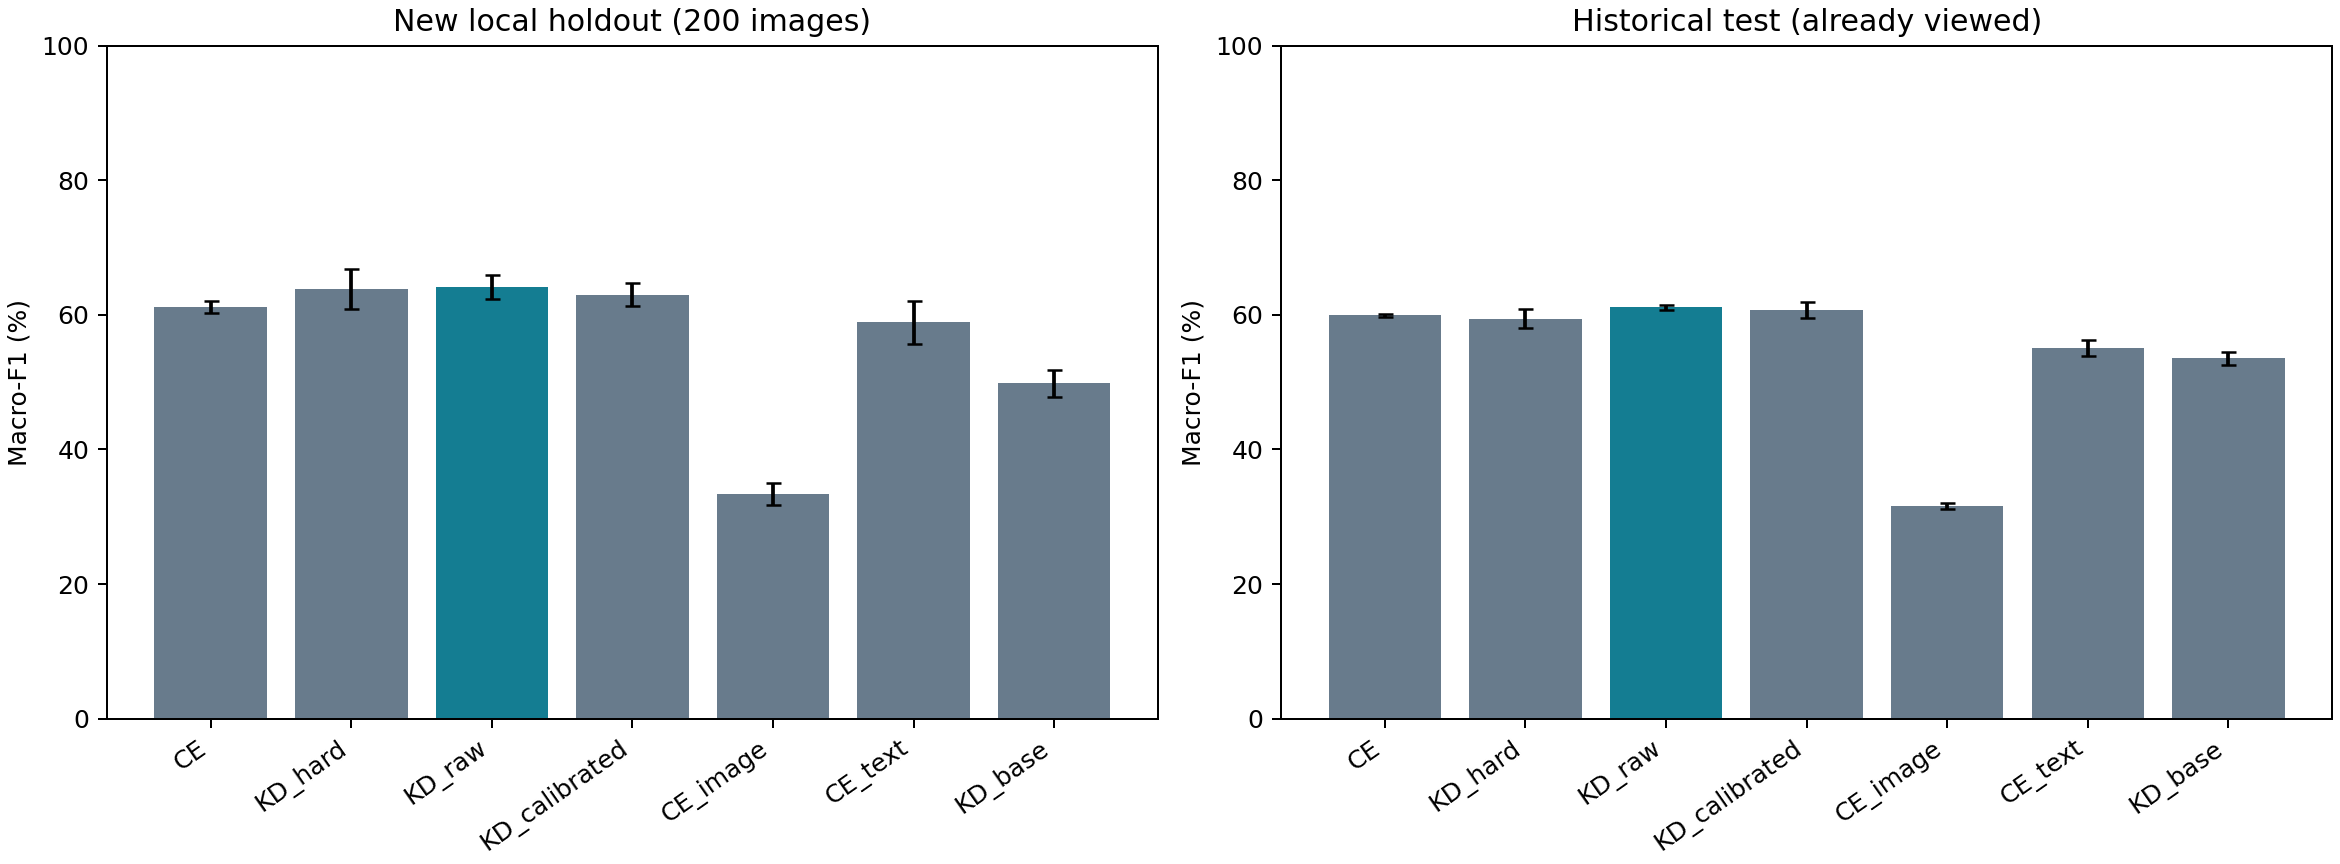

汇报目录： /content/drive/MyDrive/CLIP_Jev_final_round_20261013_v1/reports/20261013_185655_d9216b


In [12]:
report_dir=fr.build_report(ctx)
from IPython.display import Markdown,Image,display
display(Markdown((report_dir/'实验汇报.md').read_text(encoding='utf-8')))
display(Image(filename=str(report_dir/'macro_f1_comparison.png')))
print('汇报目录：',report_dir)

### 4.1 可选：分类头计时

默认跳过。计时范围仅为已缓存特征→分类头；不含CLIP编码器、图片预处理、磁盘I/O或Teacher。它不能支持“端到端比4B教师快多少”的结论。若论文主张部署效率，需要额外在同设备、相同输入/精度/批量下测量完整学生和完整Teacher，区分冷启动与热运行。

In [13]:
RUN_HEAD_BENCHMARK=False
if RUN_HEAD_BENCHMARK:
    display(pd.DataFrame(fr.head_benchmark(ctx)))
else:
    print('跳过分类头计时；本报告不宣称端到端加速比。')

跳过分类头计时；本报告不宣称端到端加速比。


### 4.2 打包成果

新ZIP包含3个base最佳模型、完整训练历史、锁定协议、评价清单、逐条预测、统计结果和汇报案例。为避免重复数百MB，18个复用模型及训练特征继续引用原1013成果包。云盘中的恢复点会保留，但不重复装入交付ZIP。

In [15]:
delivery_zip=fr.package(ctx,report_dir)
print('交付文件：',delivery_zip)
print('请同时保留原1013成果包与本次新ZIP。')
# 如需直接下载，取消下一行注释；也可在Google Drive中下载。
from google.colab import files; files.download(str(delivery_zip))

交付文件： /content/drive/MyDrive/CLIP_Jev_final_round_20261013_v1/final_round_20261013_185746_6bee2c.zip
请同时保留原1013成果包与本次新ZIP。


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 结果出来后如何判断下一步

- Jev KD优于CE且优于base KD：支持任务适配教师具有额外教学价值；还需标签平滑、教师温度/偏置拆分等开发对照，才能进一步解释机制。
- Jev KD优于CE但与base KD相近：收缩为通用VLM决策蒸馏收益，不声称Jev特有贡献。
- 校准只改善NLL/ECE：将概率质量与分类成绩分开报告，不强行宣布校准分类更优。
- 新留出上的差值很小或区间跨零：当前样本证据不足，不以验证均值替代泛化证据。
- 任何下一轮方法修改都应与本轮结论分开记录；本轮留出成绩一旦查看，不能继续称为新方法的未见最终评价。

若要继续做新方法，优先研究经核对的证据成对变化及其决策迁移；只有确认全局特征读出成为瓶颈后，再比较冻结局部交互头和CLIP微调。每种结构都需要自己的CE/KD匹配对照。